# Feature-Matching

The previous experiment (`010_feature_matching.ipynb`) had a problem: Feature-Points were matched very good between reference-image and current-image. But the Reference-Points were not around the region of interrest, but in another plane (Screws, black ring around the meter).

This experiment uses as reference.image ohly the meter dial (German: Ziffernblatt) of the water-meter. 


In [1]:
from collections.abc import Sequence

import cv2
import matplotlib.pyplot as plt
import numpy as np

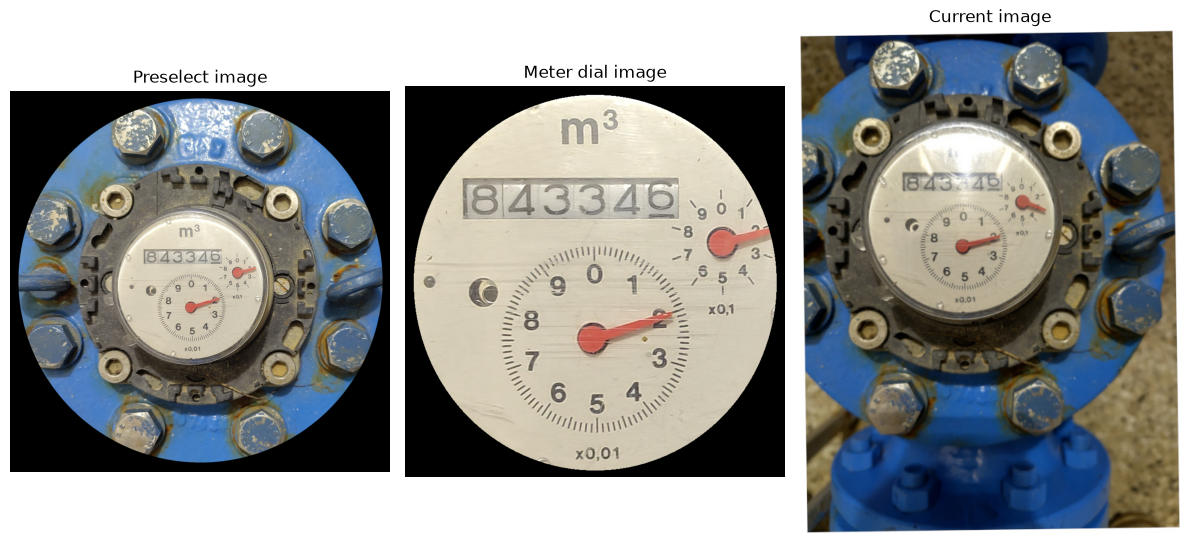

In [2]:
preselect_image : np.ndarray
meter_dial_image : np.ndarray
current_image : np.ndarray

METER_PRESELECT_IMAGE_PATH = "data/2026-10-32_Fotos_water-meter/2026-11-08_water-meter_reference-image_preselect_v2.png"
METER_DIAL_IMAGE_PATH = "data/2026-10-32_Fotos_water-meter/2026-11-08_water-meter-dial_reference-image_v3.png"
CURRENT_IMAGE_PATH = "data/2026-10-32_Fotos_water-meter/IMG_20261029_121646.jpg"

rv = cv2.imread(METER_PRESELECT_IMAGE_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Preselect image not found."
preselect_image = rv

rv = cv2.imread(METER_DIAL_IMAGE_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Meter dial image not found."
meter_dial_image = rv

rv = cv2.imread(CURRENT_IMAGE_PATH, cv2.IMREAD_UNCHANGED)
assert isinstance(rv, np.ndarray), "Current image not found."
current_image = rv

# Show images side by side using matplotlib
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
axes[0].imshow(cv2.cvtColor(preselect_image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Preselect image")
axes[1].imshow(cv2.cvtColor(meter_dial_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Meter dial image")
axes[2].imshow(cv2.cvtColor(current_image, cv2.COLOR_BGR2RGB))
axes[2].set_title("Current image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

`preselect_image` and `meter_dial_image` have an alpha-channel (`current_image` does not):

In [3]:
print(f"preselect_image.shape: {preselect_image.shape}, dtype: {preselect_image.dtype}")
print(f"meter_dial_image.shape: {meter_dial_image.shape}, dtype: {meter_dial_image.dtype}")
print(f"current_image.shape: {current_image.shape}, dtype: {current_image.dtype}")

preselect_image.shape: (2158, 2150, 4), dtype: uint8
meter_dial_image.shape: (801, 778, 4), dtype: uint8
current_image.shape: (648, 490, 3), dtype: uint8


Alpha-channel of preselect_image:

In [4]:
print(f"Masked out pixel at x=0, y=0: {preselect_image[0,0]}")
print(f"Pixel in the center of the preselect image: {preselect_image[preselect_image.shape[0]//2, preselect_image.shape[1]//2]}")

Masked out pixel at x=0, y=0: [0 0 0 0]
Pixel in the center of the preselect image: [188 207 215 255]


The Alpha-channel only contains 0 or 255 (there is no blending)

In [5]:
alpha_values, pixel_counts = np.unique(preselect_image[:, :, 3], return_counts=True)

for value, count in zip(alpha_values, pixel_counts):
    print(f"Alpha value {value}: {count} pixels")

Alpha value 0: 1306732 pixels
Alpha value 255: 3332968 pixels


# Common function for both of the following steps

This function takes a reference image, an ROI mask matching the reference image, and a current image.
It performs feature matching to compute a homography and returns the ROI mask warped into the current image, along with the RANSAC inlier point pairs. The mask must be a two-dimensional uint8 or boolean array; nearest-neighbor interpolation preserves its values. When the reference image has an alpha channel, only nontransparent reference keypoint centers are considered.

A ratio test alone can match several reference keypoints to the same current-image location. Before RANSAC, retain only the best ratio-tested match for each reference and current keypoint location.

This function contains all things worked out in the first experiment (See there for an explanation.)

In [6]:
def project_mask( cur_img: np.ndarray,
                  ref_img: np.ndarray,
                  min_keypoints: int = 15,
                  min_matches: int = 10,
                  match_ratio: float = 0.75,
                  ransac_reproj_threshold: float = 5.0
                  ) -> tuple[np.ndarray, np.ndarray, np.ndarray] | None:
    """Compute the homography between two images. Returns the homography matrix and matching 
    reference and current points that were used to compute the homography.
    If the homography cannot be computed, returns None."""
    assert cur_img.ndim == 3 and cur_img.shape[2] in (3, 4), "Current image must be a color image."
    assert ref_img.ndim == 3 and ref_img.shape[2] in (3, 4), "Reference image must be a color image."
    
    # The mask restricts keypoint centers, not the surrounding descriptor region.
    feature_search_mask = ref_img[:, :, 3] if ref_img.shape[2] == 4 else None

    # Find features (keypoints and their descriptors) in both images
    feature_extractor = cv2.SIFT.create()
    ref_kp, ref_desc = feature_extractor.detectAndCompute(ref_img, mask=feature_search_mask)
    cur_kp, cur_desc = feature_extractor.detectAndCompute(cur_img, None)
    if ref_desc is None or cur_desc is None or len(ref_kp) < min_keypoints or len(cur_kp) < min_keypoints:
        print("Not enough keypoints detected.")
        return None

    # Match features between the two images
    norm = cv2.NORM_L2 if ref_desc.dtype == np.float32 else cv2.NORM_HAMMING
    brute_force_mathcher = cv2.BFMatcher(norm, crossCheck=False)
    raw : Sequence[Sequence[cv2.DMatch]] = brute_force_mathcher.knnMatch(
                queryDescriptors=ref_desc, 
                trainDescriptors=cur_desc, 
                k=2
    )

    # Apply ratio test to filter good matches in 2 steps
    # first select canditates based on the ratio test.
    candidates = []
    for m, n in raw:
        if m.distance < match_ratio * n.distance:
            candidates.append(m)
    candidates.sort(key=lambda m: m.distance)

    # Filter out matches that share the same keypoint in either image to ensure distinct matches
    good_matches = []
    used_ref_points_indices = set()
    used_cur_points_indices = set()
    for match in candidates:
        if match.queryIdx in used_ref_points_indices or match.trainIdx in used_cur_points_indices:
            continue
        good_matches.append(match)
        used_ref_points_indices.add(match.queryIdx)
        used_cur_points_indices.add(match.trainIdx)
    if len(good_matches) < max(4, min_matches):
        print("Not enough distinct good matches found.")
        return None

    # Compute homography matrix with detected good matches
    ref_pts = np.zeros((len(good_matches), 1, 2), dtype=np.float32)
    cur_pts = np.zeros((len(good_matches), 1, 2), dtype=np.float32)
    for i, match in enumerate(good_matches):
        ref_pts[i, 0] = ref_kp[match.queryIdx].pt
        cur_pts[i, 0] = cur_kp[match.trainIdx].pt

    H, inliers = cv2.findHomography(ref_pts, cur_pts, cv2.RANSAC, ransac_reproj_threshold)
    if H is None or H.shape != (3, 3):
        print("Homography could not be computed.")
        return None
    if inliers is None or np.count_nonzero(inliers) < max(4, min_matches):
        print("Not enough inliers after RANSAC.")
        return None
    inlier_mask = inliers.ravel().astype(bool)

    return (
        H,
        ref_pts.reshape(-1, 2)[inlier_mask],
        cur_pts.reshape(-1, 2)[inlier_mask]
    )



Helper-Function to show matches:

In [7]:
def draw_matches(reference_image: np.ndarray, 
                 current_image: np.ndarray, 
                 points_reference: np.ndarray, 
                 points_current: np.ndarray
                 ) -> None:
    
    line_width: int = 3 if len(points_reference) <= 15 else 2

    SPACE = 20
    height = max(reference_image.shape[0], current_image.shape[0])
    width = reference_image.shape[1] + SPACE + current_image.shape[1]
    canvas = np.full((height, width, 3), 255, dtype=np.uint8)
    canvas[:reference_image.shape[0], :reference_image.shape[1]] = reference_image[:,:,:3]
    x_offset = reference_image.shape[1] + SPACE
    canvas[:current_image.shape[0], x_offset:] = current_image[:,:,:3]

    rng = np.random.default_rng()
    for i in range(len(points_reference)):
        color = tuple(int(c) for c in rng.integers(0, 256, size=3))

        x1, y1 = points_reference[i]
        pt_ref = (round(x1), round(y1))

        x2, y2 = points_current[i]
        pt_cur = (round(x2) + x_offset, round(y2))
        cv2.line(canvas, pt_ref, pt_cur, color, line_width)
        cv2.circle(canvas, pt_ref, 10, color, line_width)
        cv2.circle(canvas, pt_cur, 10, color, line_width)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

# First step - Preselection

Perform feature matching with `preselect_image`. The ROI mask covers the whole reference image; unlike the previous polygon, it cannot extend beyond the image boundary.

In [8]:
# Use the alpha channel of the preselect image as the reference mask
preselect_mask = preselect_image[:, :, 3] 

rv = project_mask(
    cur_img=current_image,
    ref_img=preselect_image,
)

if rv is None:
    raise RuntimeError("Feature-matching between preselect and current image failed.")

H, pts_ref, pts_cur = rv

# Transform the preselect mask into the current image using the 
# computed homography
height, width = current_image.shape[:2]
transformed_preselect_mask = cv2.warpPerspective(preselect_mask, H, (width, height), flags=cv2.INTER_NEAREST)


, 

''

The found inlier-Features:

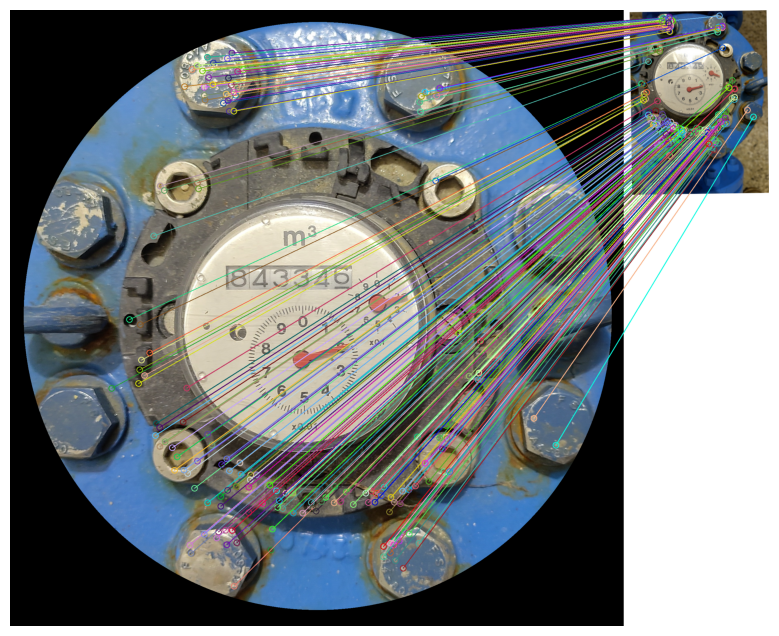

In [9]:
draw_matches(preselect_image, current_image, pts_ref, pts_cur)

Use the projected mask to blend out everything in the current image that does not belong to the preselect image:

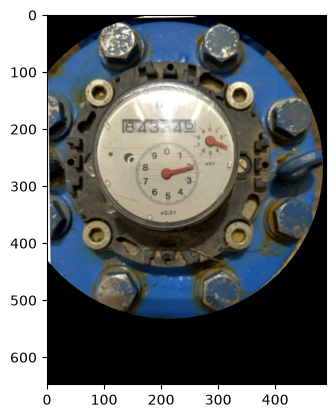

In [10]:
masked_image = cv2.bitwise_and(current_image, current_image, mask=transformed_preselect_mask)
plt.imshow(cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB))

Preselection works very well: The created mask removes regions in the `current_image` that are not visible in the `preselect_image` quite well

## Second step (first part) - Create mask for the ROI with the digits

Select the ROI in the reference image using `cv2.selectROI()`:

```python
roi_in_reference = cv2.selectROI("Select ROI in Reference Image", reference_image)
```

To avoid the need to select the ROI every time, the position and size of the ROIth was measuered with GIMP:

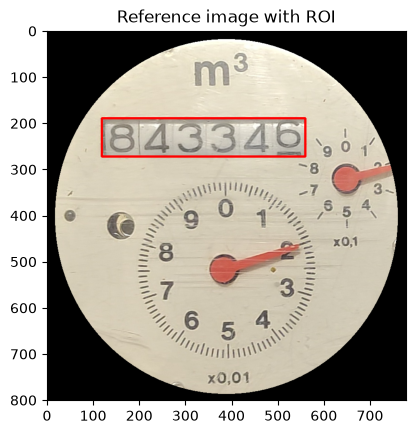

In [11]:
roi_in_reference : tuple[int,int,int,int]= (119, 189, 441, 83)  # (x, y, width, height) of the ROI in the reference image

# Plot the reference image with the ROI rectangle
meter_dial_copy = meter_dial_image.copy()
# Draw a rectangle around the ROI in the reference image
x1, y1 = roi_in_reference[0], roi_in_reference[1]
x2, y2 = x1 + roi_in_reference[2], y1 + roi_in_reference[3]
cv2.rectangle(meter_dial_copy, (x1, y1), (x2, y2), (0, 0, 255), 3)
plt.imshow(cv2.cvtColor(meter_dial_copy, cv2.COLOR_BGR2RGB))
plt.title("Reference image with ROI")
plt.show()

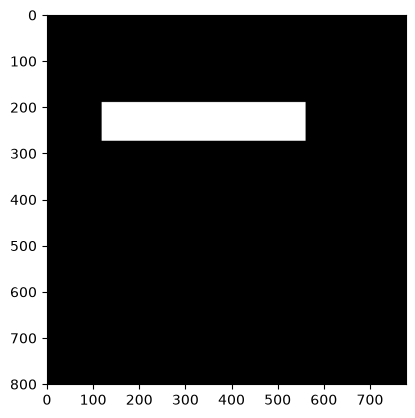

In [12]:
roi_mask = np.zeros(meter_dial_image.shape[:2], dtype=np.uint8)
# Fill the ROI rectangle in the mask with 255 (white)
x1, y1 = roi_in_reference[0], roi_in_reference[1]
x2, y2 = x1 + roi_in_reference[2], y1 + roi_in_reference[3]
roi_mask = cv2.rectangle(roi_mask, (x1, y1), (x2, y2), 255, thickness=cv2.FILLED)
plt.imshow(roi_mask, cmap='gray')

## Second-Step (second part) Project mask onto `current_image`

In [13]:
rv = project_mask(
    cur_img=current_image,
    ref_img=meter_dial_image,
    ransac_reproj_threshold=3.0
)

if rv is None:
    raise RuntimeError("Feature-matching between meter dial and current image failed.")

H, pts_meter_dial, pts_cur = rv

# Transform the preselect mask into the current image using the 
# computed homography
height, width = current_image.shape[:2]
transformed_roi_mask = cv2.warpPerspective(roi_mask, H, (width, height), flags=cv2.INTER_NEAREST)


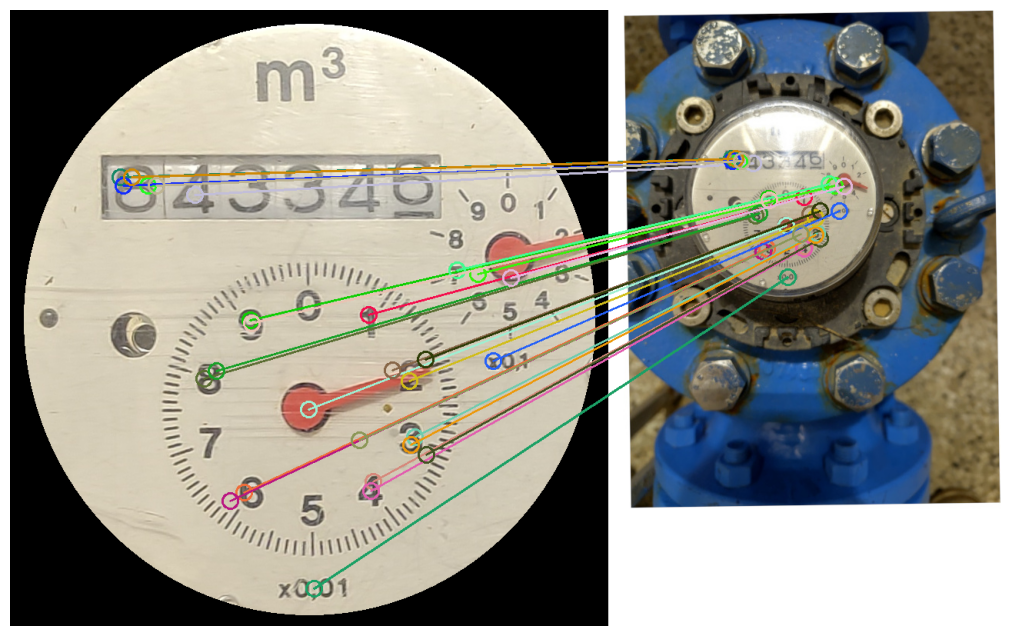

In [14]:
draw_matches(meter_dial_image, current_image, pts_meter_dial, pts_cur)

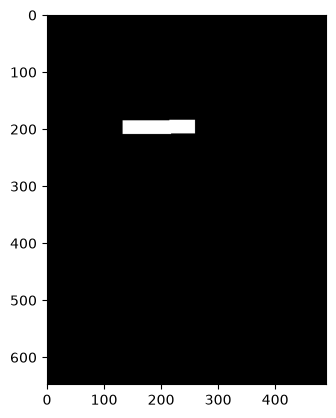

In [15]:
plt.imshow(transformed_roi_mask, cmap='gray')

Apply mask to visualize, if everthing worked:

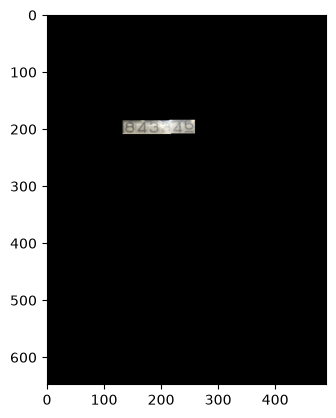

In [16]:
masked_image = cv2.bitwise_and(current_image, current_image, mask=transformed_roi_mask)
plt.imshow(cv2.cvtColor(masked_image, cv2.COLOR_BGR2RGB))

# Postprocessing

Transform the current_image back with the inverse homography (so it overlays correctly the meter_dial_image ) and use this as final image to cut out the ROI containing only the digits.

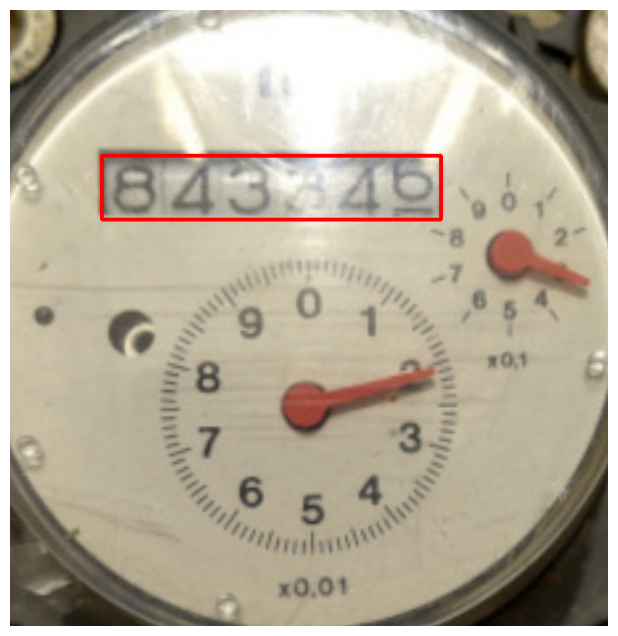

In [17]:
# Warp the current image back into the meter-dial reference coordinates.
ref_height, ref_width = meter_dial_image.shape[:2]
inverse_H = np.linalg.inv(H)

rectified_current_image = cv2.warpPerspective(
    current_image,
    inverse_H,
    (ref_width, ref_height)
)

rectified_current_image_copy = rectified_current_image.copy()
# Draw the ROI rectangle on the rectified current image
x1, y1 = roi_in_reference[0], roi_in_reference[1]
x2, y2 = x1 + roi_in_reference[2], y1 + roi_in_reference[3]
cv2.rectangle(rectified_current_image_copy, (x1, y1), (x2, y2), (0, 0, 255), 3)
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(rectified_current_image_copy, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

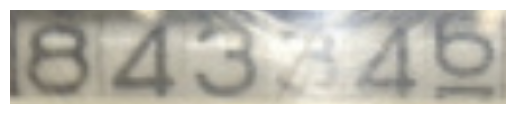

In [18]:
digits_img = rectified_current_image[y1:y2+1, x1:x2+1]
plt.imshow(cv2.cvtColor(digits_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### Conclusion: 

This works well. During developemnt of the prevous Experiment a problem was found and solved. The second computation of the homography first did not work:  feature-matching-Algorithm found many keypoints in the reference-image that matched a single point in the current_image. The homography-calculation failed (see previous experiment).

The problem is now solved: Such matchings are filteres out first (candidates --> good_matches) and only matches between differnet points are used.